# Regresión logística — issue #18
Autora: BesteOzaydin. Baseline para Económico, Medio y Premium.

Se reutiliza el contrato compartido sin modificar datos ni split. La propuesta de decisiones (rama `docs/14-modeling-decisions`, pendiente de aprobación) usa F1 macro, CV estratificada de 5 folds con semilla 42 y gap = media F1 train − media F1 validación < 0.05 (puntos absolutos). No consta acuerdo vigente en dev sobre estas dos definiciones. Se adoptan provisionalmente esas reglas. Presupuesto local: 20 trials Optuna; el presupuesto común sigue pendiente.

El split compartido usa bins provisionales globales para estratificar; los umbrales finales se calculan solo con train y quedan fijos durante CV. El test no guía selección. La CV optimizada puede ser optimista. El split aleatorio no garantiza generalización a nuevos anfitriones o fechas.


In [1]:
from pathlib import Path
import sys, json, hashlib, platform, subprocess, time, warnings, shutil, os
from importlib.metadata import version
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import optuna
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.exceptions import ConvergenceWarning
from src.preprocessing import load_train_test, build_preprocessor, TARGET_LABELS, RAW_DATA_PATH
SEED, N_TRIALS = 42, 20
LABELS = list(TARGET_LABELS)
X_train, X_test, y_train, y_test, thresholds = load_train_test(return_thresholds=True)
assert 'price' not in X_train and 'price' not in X_test
assert X_train.index.intersection(X_test.index).empty
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
print(sys.executable, platform.python_version())
print('Train/test:', X_train.shape, X_test.shape, 'Umbrales:', thresholds)
display(pd.DataFrame({'train': y_train.value_counts(), 'test': y_test.value_counts()}).reindex(LABELS))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
# Un fallo de convergencia invalida la ejecución: no se oculta.
warnings.filterwarnings('error', category=ConvergenceWarning)
def pipeline(model):
    return Pipeline([('prep', build_preprocessor()), ('model', model)])
def evaluate_cv(estimator):
    return cross_validate(estimator, X_train, y_train, cv=cv, scoring='f1_macro',
                          return_train_score=True, error_score='raise', n_jobs=1)
def summarize(scores):
    train, val = float(np.mean(scores['train_score'])), float(np.mean(scores['test_score']))
    return dict(cv_train_f1_macro=train, cv_validation_f1_macro=val,
                cv_validation_std=float(np.std(scores['test_score'])), gap=train-val,
                gap_under_005=bool(train-val < 0.05), cv_fit_seconds=float(np.sum(scores['fit_time'])))


/Users/besteozaydin/Desktop/AI_Course_Docs/P5-Cón-G6/bcn-price-classifier/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/Users/besteozaydin/Desktop/AI_Course_Docs/P5-Cón-G6/bcn-price-classifier/.venv/bin/python 3.12.5
Train/test: (10088, 71) (2522, 71) Umbrales: {'lower': 122.0, 'upper': 249.72333333333327}


,train,test
price_segment,,
Económico,3366,841
Medio,3359,840
Premium,3363,841


## Referencia Dummy y regresión sin ajustar hiperparámetros
Ambas usan el mismo Pipeline y los mismos folds. Dummy usa `most_frequent`.

In [2]:
dummy = pipeline(DummyClassifier(strategy='most_frequent', random_state=SEED))
dummy_scores = evaluate_cv(dummy)
default_scores = evaluate_cv(pipeline(LogisticRegression(solver='lbfgs', max_iter=5000, random_state=SEED)))
display(pd.DataFrame([summarize(dummy_scores), summarize(default_scores)], index=['Dummy', 'LogReg default']))


,cv_train_f1_macro,cv_validation_f1_macro,cv_validation_std,gap,gap_under_005,cv_fit_seconds
Dummy,0.166791,0.166791,0.000068,8.618269e-09,True,0.501829
LogReg default,0.782404,0.765303,0.007198,1.710058e-02,True,2.113420


## Optuna solo en train
Espacio: C log-uniforme [0.001, 100]; class_weight en {None, balanced}. Solver lbfgs, regularización L2 por defecto, max_iter=5000. TPE semilla 42, 20 trials secuenciales sin pruning. Se maximiza la media de F1 macro de validación; el gap se informa, sin consultar test para corregirlo.


In [3]:
def objective(trial):
    params = {'C': trial.suggest_float('C', 1e-3, 100.0, log=True),
              'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced'])}
    scores = evaluate_cv(pipeline(LogisticRegression(**params, solver='lbfgs', max_iter=5000, random_state=SEED)))
    trial.set_user_attr('cv_summary', summarize(scores))
    trial.set_user_attr('fold_train', scores['train_score'].tolist())
    trial.set_user_attr('fold_validation', scores['test_score'].tolist())
    return float(np.mean(scores['test_score']))
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
started = time.perf_counter()
study.optimize(objective, n_trials=N_TRIALS)
search_seconds = time.perf_counter() - started
best_summary = study.best_trial.user_attrs['cv_summary']
print('Mejor configuración:', study.best_params, 'Tiempo búsqueda:', search_seconds)
display(pd.DataFrame([best_summary]))
display(pd.DataFrame({'train_f1_macro': study.best_trial.user_attrs['fold_train'],
                      'validation_f1_macro': study.best_trial.user_attrs['fold_validation']}))
print('Requisito gap < 0.05:', best_summary['gap_under_005'])


Mejor configuración: {'C': 0.9846738873614568, 'class_weight': None} Tiempo búsqueda: 54.91028449998703


,cv_train_f1_macro,cv_validation_f1_macro,cv_validation_std,gap,gap_under_005,cv_fit_seconds
0,0.782605,0.765872,0.007133,0.016732,True,1.8309


,train_f1_macro,validation_f1_macro
0,0.782170,0.763648
1,0.783033,0.775465
2,0.781424,0.772861
3,0.782814,0.760355
4,0.783581,0.757031


Requisito gap < 0.05: True


## Evaluación final en test
Se congela la selección anterior y se ajusta con todo train. Se evalúan ambos modelos sobre exactamente el mismo test, sin cambios posteriores guiados por sus resultados. Matrices: filas = clase real según precio/umbrales; columnas = predicción.

DummyClassifier


,precision,recall,f1-score,support
Económico,0.333466,1.000000,0.500149,841.000000
Medio,0.000000,0.000000,0.000000,840.000000
Premium,0.000000,0.000000,0.000000,841.000000
accuracy,0.333466,0.333466,0.333466,0.333466
macro avg,0.111155,0.333333,0.166716,2522.000000
weighted avg,0.111199,0.333466,0.166782,2522.000000


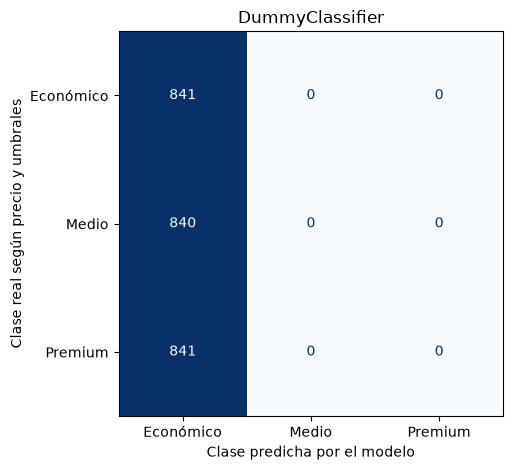

LogisticRegression


,precision,recall,f1-score,support
Económico,0.865407,0.871581,0.868483,841.000000
Medio,0.658228,0.680952,0.669397,840.000000
Premium,0.779156,0.746730,0.762599,841.000000
accuracy,0.766455,0.766455,0.766455,0.766455
macro avg,0.767597,0.766421,0.766826,2522.000000
weighted avg,0.767641,0.766455,0.766865,2522.000000


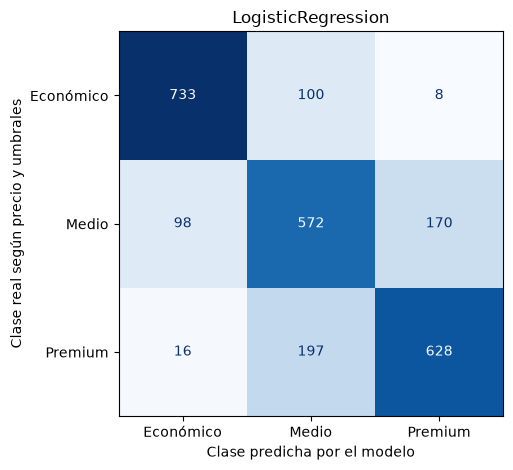

,model,cv_train_f1_macro,cv_validation_f1_macro,cv_validation_std,gap,gap_under_005,cv_fit_seconds,test_accuracy,test_f1_macro,test_extreme_error_rate,fit_seconds,predict_seconds,search_seconds,params,cv,snapshot
0,DummyClassifier,0.166791,0.166791,0.000068,8.618269e-09,True,0.501829,0.333466,0.166716,0.333466,0.124869,0.013187,0.000000,"{""strategy"": ""most_frequent""}","StratifiedKFold(5, shuffle=True, random_state=42)",2026-09-17
1,LogisticRegression,0.782605,0.765872,0.007133,1.673244e-02,True,1.830900,0.766455,0.766826,0.009516,0.553964,0.010346,54.910284,"{""C"": 0.9846738873614568, ""class_weight"": null}","StratifiedKFold(5, shuffle=True, random_state=42)",2026-09-17


In [4]:
final_model = pipeline(LogisticRegression(**study.best_params, solver='lbfgs', max_iter=5000, random_state=SEED))
rows, reports, matrices = [], {}, {}
for name, model, cv_summary in [('DummyClassifier', dummy, summarize(dummy_scores)),
                                  ('LogisticRegression', final_model, best_summary)]:
    started = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - started
    started = time.perf_counter()
    prediction = model.predict(X_test)
    predict_seconds = time.perf_counter() - started
    matrix = confusion_matrix(y_test, prediction, labels=LABELS)
    reports[name] = classification_report(y_test, prediction, labels=LABELS, output_dict=True, zero_division=0)
    matrices[name] = matrix.tolist()
    rows.append(dict(model=name, **cv_summary, test_accuracy=accuracy_score(y_test, prediction),
                     test_f1_macro=f1_score(y_test, prediction, average='macro'),
                     test_extreme_error_rate=float((matrix[0,2]+matrix[2,0])/len(y_test)),
                     fit_seconds=fit_seconds, predict_seconds=predict_seconds,
                     search_seconds=search_seconds if name == 'LogisticRegression' else 0,
                     params=json.dumps(study.best_params if name == 'LogisticRegression' else {'strategy':'most_frequent'}),
                     cv='StratifiedKFold(5, shuffle=True, random_state=42)', snapshot='2026-09-17'))
    print(name)
    display(pd.DataFrame(reports[name]).T)
    ConfusionMatrixDisplay(matrix, display_labels=LABELS).plot(cmap='Blues', colorbar=False)
    plt.xlabel('Clase predicha por el modelo')
    plt.ylabel('Clase real según precio y umbrales')
    plt.title(name)
    plt.tight_layout()
    plt.show()
comparison = pd.DataFrame(rows)
display(comparison)


## Registro reproducible y tabla común
Solo se guardan métricas agregadas, sin datos ni predicciones individuales. El notebook de comparación lee esta tabla; otros equipos pueden añadir sus filas sin volver a entrenar este modelo.

In [5]:
OUT = ROOT / 'docs' / 'results'
OUT.mkdir(parents=True, exist_ok=True)
source_hashes = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                 for p in [ROOT / 'src/preprocessing.py', ROOT / 'src/cleaning.py']}
notebook_source = json.loads((ROOT / 'notebooks/04_model_logreg.ipynb').read_text())
source_hashes['notebook_code'] = hashlib.sha256('\n'.join(''.join(c['source']) for c in notebook_source['cells'] if c['cell_type'] == 'code').encode()).hexdigest()
provenance = dict(source_hashes=source_hashes, code_state='Base commit plus notebook changes in this delivery', code_commit=subprocess.check_output([shutil.which('git', path='/opt/homebrew/bin' + os.pathsep + os.environ.get('PATH', '')) or 'git','rev-parse','HEAD'], cwd=ROOT, text=True).strip(),
                  raw_sha256=hashlib.sha256(RAW_DATA_PATH.read_bytes()).hexdigest(),
                  thresholds=thresholds, n_train=len(X_train), n_test=len(X_test), n_features=X_train.shape[1],
                  python=platform.python_version(), seed=SEED, trials=N_TRIALS,
                  versions={p:version(p) for p in ['pandas','numpy','scikit-learn','optuna','matplotlib']},
                  protocol_status='Propuesta pendiente; presupuesto local 20 trials',
                  source_notebook='notebooks/04_model_logreg.ipynb')
comparison['code_commit'] = provenance['code_commit']
comparison['raw_sha256'] = provenance['raw_sha256']
comparison.to_csv(OUT / 'logreg_comparison.csv', index=False)
(OUT / 'logreg_details.json').write_text(json.dumps(dict(provenance=provenance, reports=reports,
     confusion_matrices=matrices, best_params=study.best_params,
     folds=study.best_trial.user_attrs), ensure_ascii=False, indent=2) + '\n')
study.trials_dataframe().to_csv(OUT / 'logreg_trials.csv', index=False)
print('Resultados agregados guardados: docs/results/')


Resultados agregados guardados: docs/results/
